<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula25a_perceptron_with_bias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np

def create_dataset(n=20, coefs=[1, 1], intercept=-1):
  X = np.random.rand(n, 2)
  y = X @ coefs + intercept
  y = np.sign(y)
  return X, y

X, y = create_dataset()
print(X)
print(y)

[[0.22294112 0.39781472]
 [0.99852902 0.38204738]
 [0.71049827 0.73671523]
 [0.20443346 0.16420639]
 [0.68699345 0.30049465]
 [0.07181739 0.89646383]
 [0.18936292 0.53276488]
 [0.70548081 0.94367708]
 [0.27719484 0.34030894]
 [0.71183274 0.96614624]
 [0.73960758 0.99696053]
 [0.68479258 0.68387732]
 [0.98556488 0.98625312]
 [0.53716603 0.39439128]
 [0.23795185 0.32044659]
 [0.22167798 0.16143028]
 [0.709431   0.73093053]
 [0.21757977 0.56664371]
 [0.62742662 0.50740775]
 [0.58233333 0.58387527]]
[-1.  1.  1. -1. -1. -1. -1.  1. -1.  1.  1.  1.  1. -1. -1. -1.  1. -1.
  1.  1.]


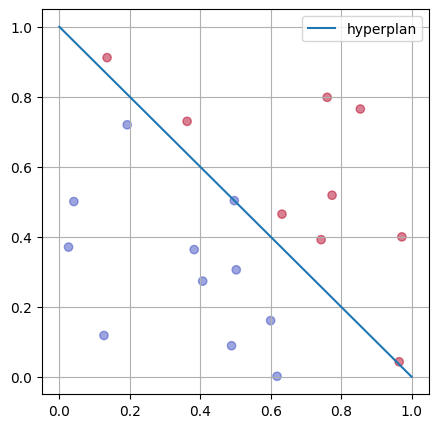

In [40]:
from matplotlib import pyplot as plt

def plot_dataset(X, y):
  plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", alpha=0.5)
  plt.grid(True)

def plot_hyperplan(coefs, intercept, legend="hyperplan"):
  xs = np.array([0,1])
  ys = -(coefs[0] * xs + intercept) / coefs[1]
  plt.plot(xs, ys, label=legend)
  plt.legend()

coefs = [1, 1]
intercept = -1
X, y = create_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept)
plt.show()

accuracy: 0.75
coefs: [ 5.64136598 -4.16855727]


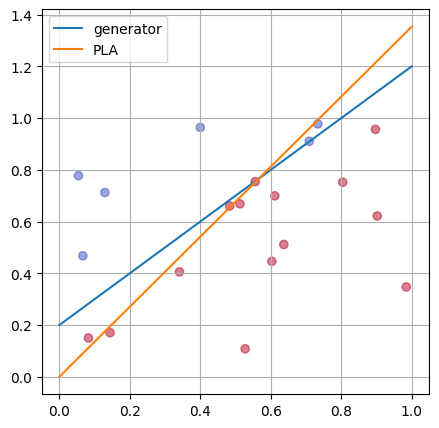

In [65]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

class PLA(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=10):
    self.max_iter = max_iter

  def fit(self, X, y):
    self.coefs = np.zeros(X.shape[1])
    # PLA - PErceptron Learning Algorithm (without bias)
    for _ in range(self.max_iter):
      cost = 0
      idx = np.arange(X.shape[0])
      np.random.shuffle(idx)
      for i in idx:
        logits = X[i] @ self.coefs
        y_pred = np.sign(logits)
        error = y[i] - y_pred
        if error != 0:
          self.coefs += error * X[i]
          cost += error**2
      if cost == 0:
        break
    return self

  def predict(self, X):
    logits = X @ self.coefs
    y_pred = np.sign(logits)
    return y_pred

coefs = [1, -1]
intercept = 0.2
X, y = create_dataset(20, coefs, intercept)

clf = PLA()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, 0, "PLA")
plt.show()

accuracy: 1.0
coefs: [6.15463414 3.95015192]


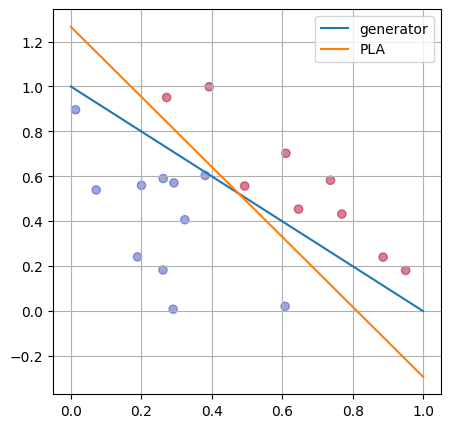

In [103]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

class PLA(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=100):
    self.max_iter = max_iter

  def fit(self, X, y):
    self.coefs = np.zeros(X.shape[1])
    self.intercept = 0
    # PLA - PErceptron Learning Algorithm (with bias)
    for _ in range(self.max_iter):
      cost = 0
      idx = np.arange(X.shape[0])
      np.random.shuffle(idx)
      for i in idx:
        logits = X[i] @ self.coefs + self.intercept
        y_pred = np.sign(logits)
        error = y[i] - y_pred
        if error != 0:
          self.coefs += error * X[i]
          self.intercept += error
          cost += error**2
      if cost == 0:
        break
    return self

  def predict(self, X):
    logits = X @ self.coefs + self.intercept
    y_pred = np.sign(logits)
    return y_pred

coefs = [1, 1]
intercept = -1
X, y = create_dataset(20, coefs, intercept)

clf = PLA()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "PLA")
plt.show()

accuracy: 0.89


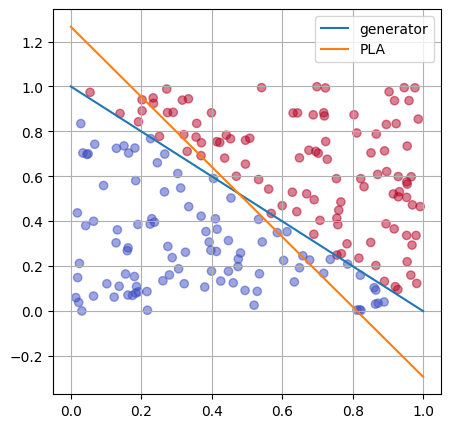

In [119]:
X_test, y_test = create_dataset(200, coefs, intercept)
y_pred = clf.predict(X_test)
print(f"accuracy: {accuracy_score(y_test, y_pred)}")

plt.figure(figsize=(5, 5))
plot_dataset(X_test, y_test)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "PLA")
plt.show()